# Background

- **Author**: `李芸榛`
- **Created At**: `2026-11-08`
- **Research Motivation and Context (why are we interested in the findings?)：**
  本組研究臺大周邊 YouBike 的借還需求與車輛供給。站點剩餘數量資料只能看到「車數變化」，看不到車從哪裡來、往哪裡去；票證刷卡的起訖（OD）交易資料可以補上這塊。這份 notebook 是正式分析前的探索性敘述統計，目的是快速掌握 OD 資料的規模、時間節律、站點分布與資料品質，作為後續需求模型與調度分析的基礎。
  - 分析資料：`data/processed/youbike_traffic_processed/YouBike_traffic_2024_v5.csv`、`data/processed/youbike_traffic_processed/YouBike_traffic_2025_v5.csv`（一列 = 一筆來源交易；借或還任一端在研究範圍 107 站內即收錄）。處理流程與欄位說明見 [youbike_traffic_station_id_v5.ipynb](../data/code/youbike_traffic_station_id_v5.ipynb)；原始欄位定義見 [YouBike_traffic_codebook.md](../data/raw/YouBike_traffic_codebook.md)。
  - 日曆：`data/processed/calendar_2024.csv`、`data/processed/calendar_2025.csv`（組員整理的上班日與臺大學期）。
  - 樣本：2024-01-01～2025-12-31 全部 17,875,272 筆旅次，未刪除任何列；異常值與疑似重複只計數、不刪除。
- **Main Findings and Takeaways：**
  1. 研究範圍高度依賴捷運接駁：捷運公館站(2號出口) 借出 1,059,785 筆、還入 1,125,630 筆，都是第一名；前 20 名熱門起訖組合中有 17 組的一端是捷運公館站。
  2. 平日有 8、12、17 點三個尖峰（17 點平均每日 2,799.09 筆最高），且早晚潮汐明顯：107 站早上與傍晚淨流量的相關係數為 −0.83，傍晚車輛大量湧入公館站（3 號、2 號出口每日各 +180.24、+178.25 輛）。
  3. 以短程為主：騎乘時長中位數 7.37 分鐘，50.05% 落在 5–15 分鐘；區內旅次中位數 5.77 分，跨出範圍的流出／流入旅次為 10.98／9.98 分。
  4. 需求跟著學期走：學期中平均每日 27,341.97 筆，寒假只有 15,652.27 筆（57.25%）；2025 年平均每日比 2024 年高 33.73%，其中一部分來自 2024 年陸續啟用的站點（96 站增加到 107 站）。
  5. 將近一半旅次跨出範圍（流出 23.72%＋流入 21.99%），單一最大外部來源是臺科大：前 4 名起訖組合都是臺科大後門／側門與公館站(2號出口)之間的往返。
- **Future Direction：**
  1. 合併站點剩餘數量 panel，比較 OD 淨流量與實際車數變化，估計調度量與缺車／滿柱時段。
  2. 釐清臺科大—公館走廊是否應納入研究範圍，或在需求模型中另外處理跨界旅次。
  3. 建立站點 × 小時借車量模型，納入平日／學期／天氣，並在控制站點數後檢驗 2024→2025 的成長。


In [1]:
# Load packages here
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # figures are saved to files and displayed as images
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from matplotlib.cbook import boxplot_stats
from IPython.display import display, Image

# Traditional Chinese font: use the first one available on this machine.
CJK_FONTS = ["Noto Sans TC", "Heiti TC", "PingFang TC", "PingFang HK", "Microsoft JhengHei",
             "Noto Sans CJK TC", "Arial Unicode MS"]
available = {f.name for f in font_manager.fontManager.ttflist}
chosen_font = next((name for name in CJK_FONTS if name in available), None)
if chosen_font is None:
    raise RuntimeError("No Traditional Chinese font found; install Noto Sans TC to render labels.")
plt.rcParams.update({"font.family": chosen_font, "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.titlesize": 12, "axes.labelsize": 10.5})
print("Chinese font:", chosen_font)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook within the student project containing AGENTS.md and templates/.")


PROJECT_ROOT = find_project_root()
FIG_DIR = PROJECT_ROOT / "finding" / "youbike_traffic_eda_figures"
FIG_DIR.mkdir(exist_ok=True)


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def fmt_int(x):
    return f"{int(round(x)):,}"


def fmt2(x):
    return f"{x:,.2f}"


def pct(x):
    return f"{100 * x:.2f}%"


def show_figure(fig, filename):
    """Save to the figure folder and display the saved PNG (keeps the notebook output self-contained)."""
    path = FIG_DIR / filename
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

Chinese font: Noto Sans TC


In [2]:
# Load input data here and please finish all the data manipulation here.
# Inputs: the v5 OD trip files (one row = one source transaction) and the team's 2024 and 2025 calendars.
INPUTS = {
    "traffic_2024": ("data/processed/youbike_traffic_processed/YouBike_traffic_2024_v5.csv",
                     "8549188af5faa11fd0a53c5dce0b178cfa76534ccbce042142af44799f205d20"),
    "traffic_2025": ("data/processed/youbike_traffic_processed/YouBike_traffic_2025_v5.csv",
                     "0ae8940ea7b1b165b9abf860ad0a6edc9cd3682f9c5cc1ff89844b5a86d8cf5a"),
    "calendar_2024": ("data/processed/calendar_2024.csv",
                      "3de23cb578c1c4d6b21d732bd1e0d38a952c56f03e07268099f82ca72211c3ac"),
    "calendar_2025": ("data/processed/calendar_2025.csv",
                      "f73dfa16d11535fba52807ae73c1d8d84e8c88ca7a2d24a508c036453c63a65d"),
}
input_paths = {}
for key, (relative_path, expected) in INPUTS.items():
    path = (PROJECT_ROOT / relative_path).resolve()
    if not path.is_relative_to((PROJECT_ROOT / "data" / "processed").resolve()):
        raise ValueError(f"Inputs must come from data/processed/: {relative_path}")
    if not path.is_file():
        raise FileNotFoundError(path)
    if sha256_file(path) != expected:
        raise ValueError(f"{relative_path} changed; identify the new version before analysis.")
    input_paths[key] = path
print(f"All {len(INPUTS)} inputs exist and match their expected SHA-256.")

TRAFFIC_COLUMNS = ["rent_time", "rent_station", "rent_station_id", "return_time", "return_station",
                   "return_station_id", "rent", "bike_type", "infodate"]
read_options = {"dtype": str, "keep_default_na": False, "na_filter": False, "encoding": "utf-8-sig"}
parts = []
for year in (2024, 2025):
    part = pd.read_csv(input_paths[f"traffic_{year}"], **read_options)
    assert list(part.columns) == TRAFFIC_COLUMNS, f"{year}: unexpected columns"
    part["source_year"] = year
    parts.append(part)
trips = pd.concat(parts, ignore_index=True)
del parts
RAW_ROWS = len(trips)

# --- Check 1: time precision is one hour -------------------------------------------------
for col in ("rent_time", "return_time"):
    assert trips[col].str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:00:00").all(), f"{col} is not hour-precision"
    trips[col] = pd.to_datetime(trips[col], format="%Y-%m-%d %H:%M:%S")
trips["date"] = pd.to_datetime(trips["infodate"], format="%Y-%m-%d")
assert (trips["date"] == trips["rent_time"].dt.normalize()).all(), "infodate differs from the rental date"

# --- Check 2: verify the -1 assumption -------------------------------------------------
OUTSIDE = "-1"
rent_in = trips["rent_station_id"] != OUTSIDE
return_in = trips["return_station_id"] != OUTSIDE
check = {
    "每筆至少一端 ID ≠ -1": bool((rent_in | return_in).all()),
    "每個非 -1 ID 只對應一個站名": bool(
        pd.concat([trips.loc[rent_in, ["rent_station_id", "rent_station"]].set_axis(["id", "name"], axis=1),
                   trips.loc[return_in, ["return_station_id", "return_station"]].set_axis(["id", "name"], axis=1)])
        .drop_duplicates().groupby("id")["name"].nunique().max() == 1),
}
in_field_names = set(trips.loc[rent_in, "rent_station"]) | set(trips.loc[return_in, "return_station"])
outside_names = set(trips.loc[~rent_in, "rent_station"]) | set(trips.loc[~return_in, "return_station"])
check["範圍內站名不會出現 ID = -1"] = not (in_field_names & outside_names)
print("Verification of the station_id = -1 assumption:", check)
assert all(check.values()), "The -1 assumption does not hold; stop and report before analysis."

# -1 cells that are not real outside station names (blank or unreadable bytes)
TOKEN = "<UNRESOLVED_UTF8_HEX:"
minus_one_names = pd.concat([trips.loc[~rent_in, "rent_station"], trips.loc[~return_in, "return_station"]])
blank_cells = int((minus_one_names == "").sum())
token_cells = int(minus_one_names.str.startswith(TOKEN).sum())
print({"-1 cells": len(minus_one_names), "blank station name": blank_cells, "unreadable-byte token": token_cells})

# --- Derived variables (small number, all documented) ----------------------------------
TYPE_ORDER = ["區內旅次", "流出旅次", "流入旅次"]
trips["trip_type"] = pd.Categorical(
    np.select([rent_in & return_in, rent_in & ~return_in], ["區內旅次", "流出旅次"], "流入旅次"),
    categories=TYPE_ORDER)
trips["rent_in_field"] = rent_in.to_numpy()
trips["return_in_field"] = return_in.to_numpy()

PREFIX = "YouBike2.0_"
for col in ("rent_station", "return_station"):
    names = trips[col].str.removeprefix(PREFIX)
    names = names.mask(names == "", "（空白站名）").mask(names.str.startswith(TOKEN), "（無法辨識的站名）")
    trips[col] = names.astype("category")

# rent ("H:MM:SS", hours may exceed 24) -> minutes
rent = trips["rent"]
assert rent.str.fullmatch(r"\d+:[0-5]\d:[0-5]\d").all(), "rent has an unexpected format"
duration_sec = (rent.str[:-6].astype(np.int64) * 3600 + rent.str[-5:-3].astype(np.int64) * 60
                + rent.str[-2:].astype(np.int64))
trips["duration_min"] = duration_sec / 60
trips["duration_hhmm"] = rent.str[:-3]          # duration without seconds, for the near-duplicate check
trips["same_station"] = trips["rent_station"].astype(str) == trips["return_station"].astype(str)
trips["rent_hour"] = trips["rent_time"].dt.hour
trips["return_hour"] = trips["return_time"].dt.hour
trips["year"] = trips["date"].dt.year
assert (trips["year"] == trips["source_year"]).all()
trips["bike_type"] = trips["bike_type"].replace("", "（未提供）").astype("category")

# --- Calendar: the team's calendar files (weekday = 1 for workdays; semester = 1 during NTU classes) ---
calendar = pd.concat([pd.read_csv(input_paths[f"calendar_{y}"], dtype={"day_off_reason": str}, keep_default_na=False)
                      for y in (2024, 2025)], ignore_index=True)
calendar["date"] = pd.to_datetime(calendar["date"], format="%Y-%m-%d")
assert calendar["date"].is_unique and len(calendar) == 731
assert calendar["date"].min() == pd.Timestamp("2024-01-01") and calendar["date"].max() == pd.Timestamp("2025-12-31")
assert calendar["weekday"].isin([0, 1]).all() and calendar["semester"].isin([0, 1]).all()
# Outside classes: June–September = summer break, otherwise winter break.
calendar["period"] = np.where(calendar["semester"] == 1, "學期中",
                              np.where(calendar["date"].dt.month.between(6, 9), "暑假", "寒假"))
calendar["day_type"] = np.where(calendar["weekday"] == 1, "平日", "假日")
semester_runs = calendar.loc[calendar["semester"] == 1, "date"]
breaks = semester_runs.diff().dt.days.fillna(1).gt(1).cumsum()
print("學期期間（依 calendar 檔）：",
      [f"{g.min():%Y-%m-%d}～{g.max():%Y-%m-%d}" for _, g in semester_runs.groupby(breaks)])

trips = trips.merge(calendar[["date", "day_type", "period"]], on="date", how="left", validate="many_to_one")
assert trips["day_type"].notna().all()
trips["day_type"] = pd.Categorical(trips["day_type"], categories=["平日", "假日"])
trips["period"] = pd.Categorical(trips["period"], categories=["學期中", "寒假", "暑假"])
trips["dow"] = trips["date"].dt.dayofweek  # 0 = Monday

# --- Sort (data are not in time order) -------------------------------------------------
trips = (trips.sort_values(["rent_time", "return_time", "rent_station", "return_station", "rent"], kind="stable")
              .reset_index(drop=True))
assert len(trips) == RAW_ROWS, "Rows were added or dropped during preparation."
print(f"Analysis sample: {RAW_ROWS:,} trips (no rows dropped).")

SHOW = ["rent_time", "rent_station", "return_time", "return_station", "trip_type", "duration_min",
        "same_station", "bike_type", "day_type", "period"]
display(trips[SHOW].head(10))

All 4 inputs exist and match their expected SHA-256.
Verification of the station_id = -1 assumption: {'每筆至少一端 ID ≠ -1': True, '每個非 -1 ID 只對應一個站名': True, '範圍內站名不會出現 ID = -1': True}
{'-1 cells': 8170954, 'blank station name': 4, 'unreadable-byte token': 885}
學期期間（依 calendar 檔）： ['2024-02-19～2024-06-09', '2024-09-02～2024-12-20', '2025-02-17～2025-06-06', '2025-09-01～2025-12-19']
Analysis sample: 17,875,272 trips (no rows dropped).


,rent_time,rent_station,return_time,return_station,trip_type,duration_min,same_station,bike_type,day_type,period
0,2024-01-01,中崙福成宮,2024-01-01,捷運科技大樓站,流入旅次,16.783333,False,（未提供）,假日,寒假
1,2024-01-01,仁愛國中,2024-01-01,和平復興路口西北側,流入旅次,13.666667,False,（未提供）,假日,寒假
2,2024-01-01,仁愛安和路口,2024-01-01,新生南路三段66號前,流入旅次,26.150000,False,（未提供）,假日,寒假
3,2024-01-01,仁愛延吉路口(西北側),2024-01-01,臺大男一舍前,流入旅次,24.150000,False,（未提供）,假日,寒假
4,2024-01-01,仁愛延吉路口(西北側),2024-01-01,臺大男一舍前,流入旅次,24.433333,False,（未提供）,假日,寒假
5,2024-01-01,克勤新村,2024-01-01,捷運公館站(2號出口),流入旅次,32.866667,False,（未提供）,假日,寒假
6,2024-01-01,吳興公車總站,2024-01-01,臺大明達館北側(員工宿舍),流入旅次,26.766667,False,（未提供）,假日,寒假
7,2024-01-01,吳興公車總站,2024-01-01,臺大明達館北側(員工宿舍),流入旅次,26.816667,False,（未提供）,假日,寒假
8,2024-01-01,吳興街284巷(廣安宮),2024-01-01,臺大男七舍前,流入旅次,13.583333,False,（未提供）,假日,寒假
9,2024-01-01,和平復興路口西北側,2024-01-01,全安公園,流出旅次,7.650000,False,（未提供）,假日,寒假


In [3]:
# Summary statistics for every variable used below (N = all trips, 2024-2025 v5).
N = len(trips)
numeric_vars = {"duration_min": "騎乘時長（分鐘，rent 欄換算）", "rent_hour": "借車小時（0–23）",
                "return_hour": "還車小時（0–23）"}
numeric_summary = pd.DataFrame({
    label: {"N（有效）": fmt_int(trips[col].notna().sum()), "缺值 N": fmt_int(trips[col].isna().sum()),
            "平均數": fmt2(trips[col].mean()), "標準差": fmt2(trips[col].std()), "最小值": fmt2(trips[col].min()),
            "P25": fmt2(trips[col].quantile(.25)), "中位數": fmt2(trips[col].median()),
            "P75": fmt2(trips[col].quantile(.75)), "最大值": fmt2(trips[col].max())}
    for col, label in numeric_vars.items()}).T
print(f"表 0-1　數值變數摘要（N = {N:,} 筆旅次）")
display(numeric_summary)

categorical_vars = {"trip_type": "旅次類型", "year": "年度", "day_type": "日別（平日／假日）",
                    "period": "學期期間", "bike_type": "車種", "same_station": "同站借還",
                    "rent_station": "借車站（含範圍外）", "return_station": "還車站（含範圍外）"}
rows = []
for col, label in categorical_vars.items():
    counts = trips[col].value_counts(dropna=False)
    nonmissing = int(trips[col].notna().sum())
    for rank, (value, count) in enumerate(counts.head(10).items(), start=1):
        rows.append({"變數": label, "類別數": counts.size, "排名": rank, "類別": value,
                     "筆數": fmt_int(count), "占比（分母 = 非缺值 N）": pct(count / nonmissing),
                     "非缺值 N": fmt_int(nonmissing), "缺值 N": fmt_int(N - nonmissing)})
print(f"表 0-2　類別變數摘要：前 10 大類別（類別少於 10 時全列）")
display(pd.DataFrame(rows).set_index(["變數", "排名"]))

表 0-1　數值變數摘要（N = 17,875,272 筆旅次）


,N（有效）,缺值 N,平均數,標準差,最小值,P25,中位數,P75,最大值
騎乘時長（分鐘，rent 欄換算）,"17,875,272",0,12.63,"1,244.98",0.00,4.65,7.37,13.33,"5,258,885.15"
借車小時（0–23）,"17,875,272",0,14.24,4.65,0.00,11.00,15.00,18.00,23.00
還車小時（0–23）,"17,875,272",0,14.37,4.70,0.00,11.00,15.00,18.00,23.00


表 0-2　類別變數摘要：前 10 大類別（類別少於 10 時全列）


類別數           類別          筆數 占比（分母 = 非缺值 N）       非缺值 N 缺值 N
變數        排名                                                               
旅次類型      1      3         區內旅次   9,704,318         54.29%  17,875,272    0
          2      3         流出旅次   4,239,353         23.72%  17,875,272    0
          3      3         流入旅次   3,931,601         21.99%  17,875,272    0
年度        1      2         2025  10,215,445         57.15%  17,875,272    0
          2      2         2024   7,659,827         42.85%  17,875,272    0
日別（平日／假日） 1      2           平日  13,633,507         76.27%  17,875,272    0
          2      2           假日   4,241,765         23.73%  17,875,272    0
學期期間      1      3          學期中  12,085,151         67.61%  17,875,272    0
          2      3           暑假   3,927,501         21.97%  17,875,272    0
          3      3           寒假   1,862,620         10.42%  17,875,272    0
車種        1      3          一般車  11,717,427         65.55%  17,875,272    0
          2      3        （未提供）   5,901,955         33.02%  17,875,272    0
          3      3          電輔車     255,890          1.43%  17,875,272    0
同站借還      1      2        False  17,407,359         97.38%  17,875,272    0
          2      2         True     467,913          2.62%  17,875,272    0
借車站（含範圍外） 1   1638  捷運公館站(2號出口)   1,059,785          5.93%  17,875,272    0
          2   1638  捷運公館站(3號出口)     661,328          3.70%  17,875,272    0
          3   1638      捷運科技大樓站     650,484          3.64%  17,875,272    0
          4   1638  臺大第一活動中心西南側     396,275          2.22%  17,875,272    0
          5   1638    臺大新體育館東南側     307,849          1.72%  17,875,272    0
          6   1638      臺大小福樓東側     297,480          1.66%  17,875,272    0
          7   1638       臺大男一舍前     283,023          1.58%  17,875,272    0
          8   1638      臺大社科院西側     252,191          1.41%  17,875,272    0
          9   1638     臺灣科技大學側門     243,585          1.36%  17,875,272    0
          10  1638     臺灣科技大學後門     242,262          1.36%  17,875,272    0
還車站（含範圍外） 1   2690  捷運公館站(2號出口)   1,125,630          6.30%  17,875,272    0
          2   2690  捷運公館站(3號出口)     700,731          3.92%  17,875,272    0
          3   2690      捷運科技大樓站     629,562          3.52%  17,875,272    0
          4   2690  臺大第一活動中心西南側     426,877          2.39%  17,875,272    0
          5   2690      臺大小福樓東側     316,283          1.77%  17,875,272    0
          6   2690    臺大新體育館東南側     314,664          1.76%  17,875,272    0
          7   2690       臺大男一舍前     272,962          1.53%  17,875,272    0
          8   2690     臺灣科技大學後門     258,804          1.45%  17,875,272    0
          9   2690      臺大社科院西側     251,646          1.41%  17,875,272    0
          10  2690     臺大女九舍西南側     246,904          1.38%  17,875,272    0

### The actual analysis starts below

## 1. 資料概況

In [4]:
# 1. 資料概況：筆數、期間、站點數、三類旅次
n_days = trips["date"].nunique()
calendar_days = (trips["date"].max() - trips["date"].min()).days + 1
in_field_stations = sorted(set(trips.loc[trips["rent_in_field"], "rent_station"])
                           | set(trips.loc[trips["return_in_field"], "return_station"]))
outside_stations = (set(trips.loc[~trips["rent_in_field"], "rent_station"])
                    | set(trips.loc[~trips["return_in_field"], "return_station"])) - {"（空白站名）", "（無法辨識的站名）"}
overview = pd.DataFrame({
    "項目": ["總筆數", "2024 年筆數", "2025 年筆數", "期間（借車日）", "有資料的日數 / 日曆日數",
           "範圍內站點數（有出現的 StationID）", "範圍外站點數（不同站名，不含空白與無法辨識）"],
    "數值": [fmt_int(N), fmt_int((trips["year"] == 2024).sum()), fmt_int((trips["year"] == 2025).sum()),
           f"{trips['date'].min():%Y-%m-%d} ～ {trips['date'].max():%Y-%m-%d}", f"{n_days:,} / {calendar_days:,}",
           fmt_int(len(in_field_stations)), fmt_int(len(outside_stations))]})
print(f"表 1-1　資料概況（N = {N:,}）")
display(overview.set_index("項目"))

type_table = pd.crosstab(trips["trip_type"], trips["year"], margins=True, margins_name="合計")
type_share = type_table.div(type_table.loc["合計"], axis=1)
type_out = pd.DataFrame({f"{c} 筆數": type_table[c].map(fmt_int) for c in type_table.columns})
for c in type_table.columns:
    type_out[f"{c} 占比"] = type_share[c].map(pct)
type_out = type_out[[f"{c} {k}" for c in type_table.columns for k in ("筆數", "占比")]]
print("表 1-2　三類旅次筆數與占比（占比分母 = 該年度全部旅次）")
display(type_out)

表 1-1　資料概況（N = 17,875,272）


,數值
項目,
總筆數,"17,875,272"
2024 年筆數,"7,659,827"
2025 年筆數,"10,215,445"
期間（借車日）,2024-01-01 ～ 2025-12-31
有資料的日數 / 日曆日數,729 / 731
範圍內站點數（有出現的 StationID）,107
範圍外站點數（不同站名，不含空白與無法辨識）,"2,632"


表 1-2　三類旅次筆數與占比（占比分母 = 該年度全部旅次）


,2024 筆數,2024 占比,2025 筆數,2025 占比,合計 筆數,合計 占比
trip_type,,,,,,
區內旅次,"4,154,037",54.23%,"5,550,281",54.33%,"9,704,318",54.29%
流出旅次,"1,824,539",23.82%,"2,414,814",23.64%,"4,239,353",23.72%
流入旅次,"1,681,251",21.95%,"2,250,350",22.03%,"3,931,601",21.99%
合計,"7,659,827",100.00%,"10,215,445",100.00%,"17,875,272",100.00%


**解讀：** 兩年共 17,875,272 筆旅次（2024 年 7,659,827 筆、2025 年 10,215,445 筆）。731 天中只有 2 天完全沒有交易，都是颱風假（2024-07-25、2024-10-03）。研究範圍內 107 站都有交易，與它們往來的範圍外站名有 2,632 個。三類旅次的占比兩年幾乎相同：區內 54.29%、流出 23.72%、流入 21.99%；流出比流入多 307,752 筆。

**`station_id = -1` 的驗證：** 「每筆至少一端 ID ≠ -1」成立；每個非 -1 的 ID 只對應一個站名；範圍內站名也從未以 -1 出現，所以 -1 確實代表範圍外。唯一例外是 -1 欄位中有 4 格空白站名、885 格無法辨識的站名（亂碼 bytes），身分不明，本報告併入範圍外。

### 1.1 缺值與異常值

In [5]:
# 1（續）缺值、異常值、時間一致性、同站借還、疑似重複
dur = trips["duration_min"]
# Hour-precision consistency: the true return time lies in [rent hour, rent hour + 1h) + duration,
# so the hour gap must be floor(d/60) or floor(d/60) + 1 if both stamps are floored to the hour.
gap_hours = (trips["return_time"] - trips["rent_time"]).dt.total_seconds() / 3600
lo = np.floor(dur / 60)
gap_inconsistent = ~((gap_hours == lo) | (gap_hours == lo + 1))

exact_dup = trips.duplicated(TRAFFIC_COLUMNS[:6] + ["rent", "bike_type", "infodate"], keep=False)
near_keys = ["rent_time", "return_time", "rent_station", "return_station", "duration_hhmm"]
near_size = trips.groupby(near_keys, observed=True, sort=False)["rent"].transform("size")
near_dup = near_size > 1
near_groups = trips.loc[near_dup].groupby(near_keys, observed=True, sort=False).ngroups

quality = pd.DataFrame([
    ("借車站名空白", (trips["rent_station"] == "（空白站名）").sum()),
    ("還車站名空白", (trips["return_station"] == "（空白站名）").sum()),
    ("站名含無法辨識的 bytes（借或還）", ((trips["rent_station"] == "（無法辨識的站名）")
                                  | (trips["return_station"] == "（無法辨識的站名）")).sum()),
    ("車種未提供（2024-01～10 原始檔無此欄）", (trips["bike_type"] == "（未提供）").sum()),
    ("時長 = 0 秒", (dur == 0).sum()),
    ("時長 ≤ 1 分鐘", (dur <= 1).sum()),
    ("時長 > 4 小時", (dur > 240).sum()),
    ("時長 > 24 小時", (dur > 1440).sum()),
    ("還車時間早於借車時間", (gap_hours < 0).sum()),
    ("借還小時差與 rent 時長不一致", gap_inconsistent.sum()),
    ("同站借還", trips["same_station"].sum()),
    ("完全重複（9 欄全同，含秒數）", exact_dup.sum()),
    ("疑似重複：同借還小時、同起訖站、時長同到分鐘（只差秒數）", near_dup.sum()),
], columns=["項目", "筆數"])
quality["占全部旅次"] = (quality["筆數"] / N).map(pct)
quality["筆數"] = quality["筆數"].map(fmt_int)
print(f"表 1-3　缺值與異常值（N = {N:,}；本表只計數，不刪除任何列）")
display(quality.set_index("項目"))
print(f"疑似重複共 {near_groups:,} 組；若每組只算 1 筆，會少 {near_dup.sum() - near_groups:,} 筆。")
print("時長最大值：", fmt2(dur.max()), "分鐘 ≈", fmt2(dur.max() / 60 / 24 / 365), "年")
print("與 rent 不一致的借還小時差（前 5 筆）：")
display(trips.loc[gap_inconsistent, ["rent_time", "return_time", "rent", "rent_station", "return_station"]].head(5))

表 1-3　缺值與異常值（N = 17,875,272；本表只計數，不刪除任何列）


,筆數,占全部旅次
項目,,
借車站名空白,1,0.00%
還車站名空白,3,0.00%
站名含無法辨識的 bytes（借或還）,885,0.00%
車種未提供（2024-01～10 原始檔無此欄）,"5,901,955",33.02%
時長 = 0 秒,23,0.00%
時長 ≤ 1 分鐘,"25,248",0.14%
時長 > 4 小時,"14,790",0.08%
時長 > 24 小時,"1,145",0.01%
還車時間早於借車時間,0,0.00%


疑似重複共 1,311,851 組；若每組只算 1 筆，會少 1,812,536 筆。
時長最大值： 5,258,885.15 分鐘 ≈ 10.01 年
與 rent 不一致的借還小時差（前 5 筆）：


,rent_time,return_time,rent,rent_station,return_station
3130677,2024-07-15 16:00:00,2024-07-15 16:00:00,03:08:20,復興南路二段340巷口,復興南路二段340巷口
3130678,2024-07-15 16:00:00,2024-07-15 16:00:00,03:08:20,復興南路二段340巷口,復興南路二段340巷口
3130679,2024-07-15 16:00:00,2024-07-15 16:00:00,03:08:20,復興南路二段340巷口,復興南路二段340巷口
5783818,2024-10-26 14:00:00,2024-10-26 14:00:00,01:38:17,捷運公館站(4號出口),羅斯福路四段108巷口
5900152,2024-10-30 18:00:00,2024-10-30 20:00:00,05:33:25,臺大工綜館南側,臺大黑森林西側


**解讀：** 缺值很少：空白站名 4 格，無法辨識的站名 885 筆。車種有 33.02%（5,901,955 筆）未提供，原因是 2024-01～10 的原始檔本來就沒有這一欄。時長 ≤ 1 分鐘有 25,248 筆（0.14%），> 4 小時有 14,790 筆（0.08%）；最長一筆換算約 10.01 年，明顯是錯誤值。因此時長的平均數和標準差不可靠，後文以中位數和四分位數為主。

**重複紀錄：** 完全重複（9 欄連秒數都相同）有 152,572 筆（0.85%），比較像紀錄重複。「只差秒數」的疑似重複有 3,124,387 筆（17.48%，1,311,851 組），但這個數字應該當作上限：時間只到小時，熱門路線在同一小時、時長又同到分鐘的獨立旅次本來就很常見，所以它同時包含結伴同行和巧合。依指示，這些紀錄都沒有刪除。另外，借還小時差和 `rent` 時長對不上的只有 16 筆。

### 1.2 同站借還

In [6]:
# 1（續）同站借還：數量與時長分布（與其他區內旅次比較）
same = trips["same_station"]
print("同站借還的旅次類型分布：", trips.loc[same, "trip_type"].value_counts().to_dict())
inside = trips["trip_type"] == "區內旅次"
bins = [-0.001, 1, 2, 5, 10, 30, 60, 240, np.inf]
labels = ["≤1", "1–2", "2–5", "5–10", "10–30", "30–60", "60–240", ">240"]


def duration_profile(series):
    shares = pd.cut(series, bins=bins, labels=labels).value_counts(normalize=True).reindex(labels)
    out = {"N": fmt_int(len(series)), "中位數（分）": fmt2(series.median()), "P25": fmt2(series.quantile(.25)),
           "P75": fmt2(series.quantile(.75)), "P95": fmt2(series.quantile(.95))}
    out.update({f"{lab} 分": pct(v) for lab, v in shares.items()})
    return out


same_table = pd.DataFrame({"同站借還": duration_profile(trips.loc[same, "duration_min"]),
                           "區內其他旅次（不同站）": duration_profile(trips.loc[inside & ~same, "duration_min"])}).T
print(f"表 1-4　同站借還與其他區內旅次的時長分布（同站 N = {same.sum():,}，"
      f"占全部旅次 {pct(same.mean())}、占區內旅次 {pct(same[inside].mean())}）")
display(same_table)
top_same = trips.loc[same, "rent_station"].value_counts().head(10)
print("同站借還最多的 10 站：")
display(pd.DataFrame({"同站借還筆數": top_same.map(fmt_int),
                      "占該站借出量": (top_same / trips.loc[trips["rent_in_field"], "rent_station"]
                                    .value_counts().reindex(top_same.index)).map(pct)}))

同站借還的旅次類型分布： {'區內旅次': 467913, '流出旅次': 0, '流入旅次': 0}
表 1-4　同站借還與其他區內旅次的時長分布（同站 N = 467,913，占全部旅次 2.62%、占區內旅次 4.82%）


,N,中位數（分）,P25,P75,P95,≤1 分,1–2 分,2–5 分,5–10 分,10–30 分,30–60 分,60–240 分,>240 分
同站借還,"467,913",19.02,12.00,32.12,87.12,0.45%,0.08%,0.15%,16.27%,55.61%,17.45%,9.66%,0.32%
區內其他旅次（不同站）,"9,236,405",5.57,3.82,8.47,23.22,0.23%,3.52%,38.90%,38.74%,15.38%,2.10%,1.05%,0.08%


同站借還最多的 10 站：


,同站借還筆數,占該站借出量
rent_station,,
敦親公園,"14,859",7.89%
捷運公館站(2號出口),"13,736",1.30%
捷運科技大樓站,"12,571",1.93%
臺大小福樓東側,"12,061",4.05%
捷運公館站(3號出口),"11,839",1.79%
臺大第一活動中心西南側,"11,447",2.89%
臺大凝態館南側,"9,979",8.93%
臺大社科院西側,"9,117",3.62%
臺大天文數學館南側,"8,704",7.91%


**解讀：** 同站借還有 467,913 筆（全部旅次的 2.62%），全部屬於區內旅次，占區內旅次 4.82%。它的時長中位數 19.02 分，遠高於區內不同站旅次的 5.57 分；55.61% 落在 10–30 分鐘，≤ 1 分鐘只占 0.45%。所以大多數比較像騎一圈再還回原站，而不是借車失敗。同站借還占該站借出量比例最高的是臺大凝態館南側（8.93%）、臺大天文數學館南側（7.91%）和敦親公園（7.89%）。

## 2. 騎乘時長

表 2-1　騎乘時長敘述統計（單位：分鐘）


,N,平均數,中位數,標準差,P25,P75,P95,偏態
全部旅次,"17,875,272",12.63,7.37,"1,244.98",4.65,13.33,32.43,"4,216.39"
區內旅次,"9,704,318",10.53,5.77,"1,688.62",3.90,9.13,27.72,"3,112.56"
流出旅次,"4,239,353",15.98,10.98,81.67,6.55,18.15,39.07,495.41
流入旅次,"3,931,601",14.22,9.98,41.02,6.05,16.48,34.07,234.75
全部（排除 ≤1 分與 >4 小時）,"17,835,234",11.78,7.37,15.12,4.65,13.32,32.17,5.65


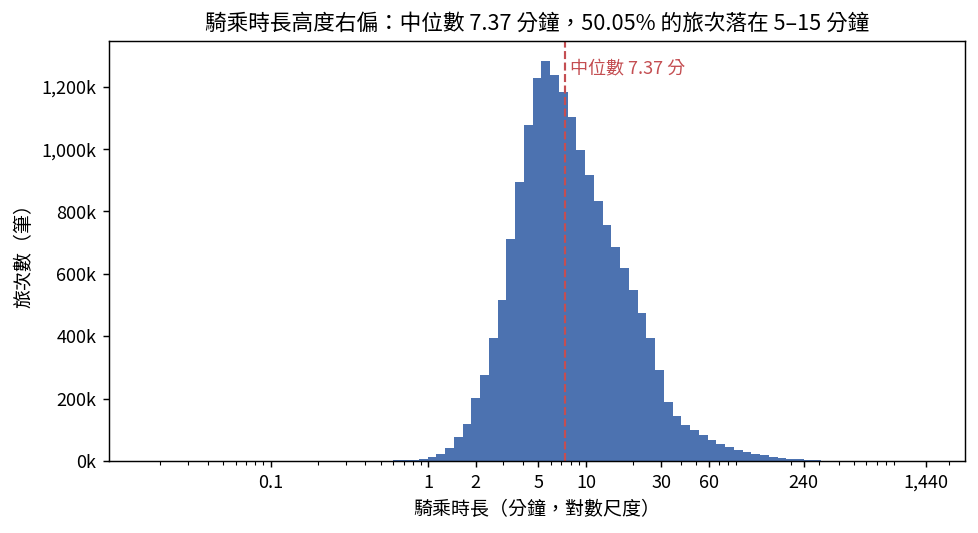

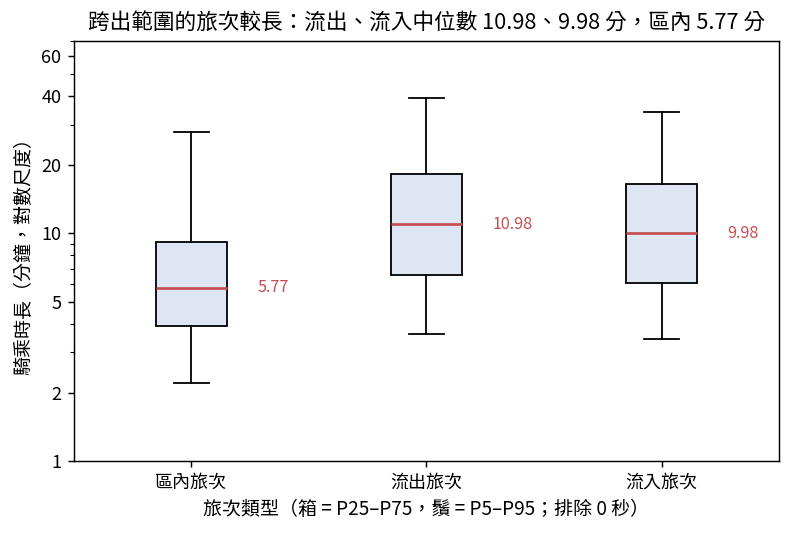

In [7]:
# 2. 騎乘時長：敘述統計、直方圖（log 尺度）、三類旅次盒鬚圖


def describe_duration(series):
    return {"N": fmt_int(len(series)), "平均數": fmt2(series.mean()), "中位數": fmt2(series.median()),
            "標準差": fmt2(series.std()), "P25": fmt2(series.quantile(.25)), "P75": fmt2(series.quantile(.75)),
            "P95": fmt2(series.quantile(.95)), "偏態": fmt2(series.skew())}


dur_table = {"全部旅次": describe_duration(trips["duration_min"])}
for t in TYPE_ORDER:
    dur_table[t] = describe_duration(trips.loc[trips["trip_type"] == t, "duration_min"])
trimmed = trips.loc[trips["duration_min"].between(1, 240, inclusive="right"), "duration_min"]
dur_table["全部（排除 ≤1 分與 >4 小時）"] = describe_duration(trimmed)
print("表 2-1　騎乘時長敘述統計（單位：分鐘）")
display(pd.DataFrame(dur_table).T)

# Histogram on a log x-axis (positive durations up to 24 h; >24 h and 0 s are counted in table 1-3).
plot_dur = trips.loc[(trips["duration_min"] > 0) & (trips["duration_min"] <= 1440), "duration_min"]
median_all = trips["duration_min"].median()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(plot_dur, bins=np.logspace(np.log10(plot_dur.min()), np.log10(1440), 90), color="#4C72B0")
ax.set_xscale("log")
ax.axvline(median_all, color="#C44E52", linestyle="--", linewidth=1.2)
ax.text(median_all * 1.08, ax.get_ylim()[1] * 0.92, f"中位數 {median_all:.2f} 分", color="#C44E52")
ax.set_xticks([0.1, 1, 2, 5, 10, 30, 60, 240, 1440])
ax.set_xticklabels(["0.1", "1", "2", "5", "10", "30", "60", "240", "1,440"])
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
share_5_15 = trips["duration_min"].between(5, 15).mean()
ax.set_title(f"騎乘時長高度右偏：中位數 {median_all:.2f} 分鐘，{pct(share_5_15)} 的旅次落在 5–15 分鐘")
ax.set_xlabel("騎乘時長（分鐘，對數尺度）")
ax.set_ylabel("旅次數（筆）")
show_figure(fig, "fig2a_duration_hist.png")

# Box plot by trip type: box = P25–P75, whiskers = P5–P95, outliers not drawn; log y-axis.
stats = []
for t in TYPE_ORDER:
    values = trips.loc[(trips["trip_type"] == t) & (trips["duration_min"] > 0), "duration_min"].to_numpy()
    s = boxplot_stats(values, whis=(5, 95))[0]
    s["label"] = t
    s["fliers"] = []
    stats.append(s)
medians = {s["label"]: s["med"] for s in stats}
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bxp(stats, showfliers=False, patch_artist=True,
       boxprops={"facecolor": "#DDE6F2"}, medianprops={"color": "#C44E52", "linewidth": 1.5})
ax.set_yscale("log")
ax.set_yticks([1, 2, 5, 10, 20, 40, 60])
ax.set_yticklabels(["1", "2", "5", "10", "20", "40", "60"])
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_ylim(1, 70)
for i, s in enumerate(stats, start=1):
    ax.text(i + 0.28, s["med"], f"{s['med']:.2f}", va="center", fontsize=9, color="#C44E52")
ax.set_title(f"跨出範圍的旅次較長：流出、流入中位數 {medians['流出旅次']:.2f}、{medians['流入旅次']:.2f} 分，"
             f"區內 {medians['區內旅次']:.2f} 分")
ax.set_xlabel("旅次類型（箱 = P25–P75，鬚 = P5–P95；排除 0 秒）")
ax.set_ylabel("騎乘時長（分鐘，對數尺度）")
show_figure(fig, "fig2b_duration_box_by_type.png")

**解讀：** 騎乘時長高度右偏。全部旅次的中位數是 7.37 分、P75 是 13.33 分、P95 是 32.43 分，但平均數 12.63、標準差 1,244.98、偏態 4,216.39 都被少數極端值拉高。排除 ≤ 1 分和 > 4 小時的紀錄後，標準差降到 15.12、偏態降到 5.65，中位數則維持 7.37 分。在對數尺度下直方圖接近單峰，50.05% 的旅次落在 5–15 分鐘。

盒鬚圖顯示跨出範圍的旅次比較長：流出、流入的中位數是 10.98 和 9.98 分，區內只有 5.77 分。這符合「區內旅次多半是校園內短程移動」的預期。

## 3. 時間分布

### 3.1 每小時借車量（平日 vs. 假日）

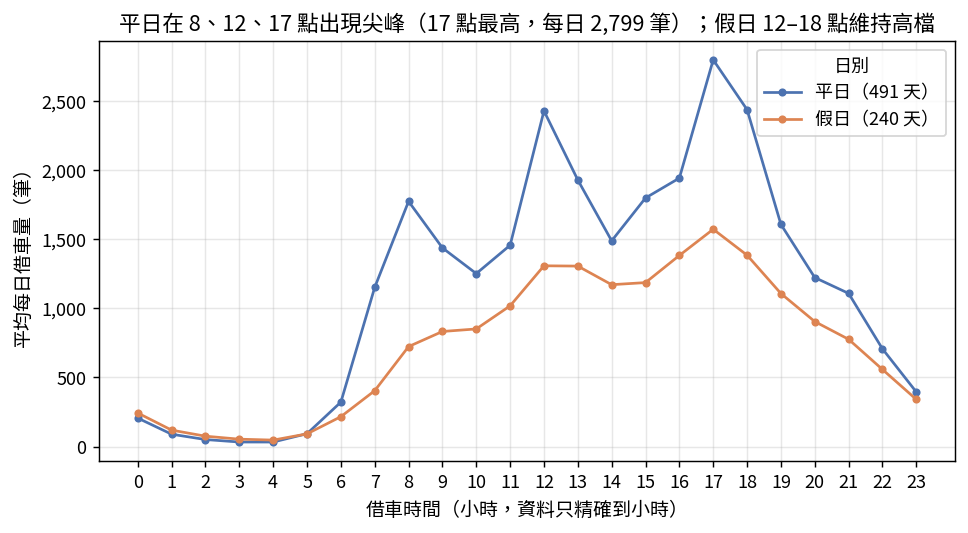

平日尖峰小時： [8, 12, 17] ；假日達最高值 80% 以上的小時： [12, 13, 16, 17, 18]
表 3-1　各小時平均每日借車量（筆）


rent_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,,,,
假日,242.67,118.70,74.80,53.21,46.60,91.62,216.10,404.25,723.40,832.77,851.09,"1,018.38","1,308.22","1,306.10","1,171.47","1,186.63","1,383.17","1,572.76","1,385.00","1,107.62",904.60,776.19,557.76,340.92
平日,205.73,89.08,50.52,32.52,32.56,92.72,321.57,"1,152.21","1,774.58","1,437.77","1,251.79","1,456.99","2,429.51","1,929.29","1,488.98","1,799.09","1,943.16","2,799.09","2,438.48","1,607.91","1,223.07","1,108.48",706.98,394.76


In [8]:
# 3-1. 每小時借車量：平日、假日分開（每日平均，避免平日天數較多造成偏誤）
days_by_type = calendar.groupby("day_type")["date"].nunique()
hourly = (trips.groupby(["day_type", "rent_hour"], observed=True).size().unstack(0)
          .div(days_by_type, axis=1))
peak = {t: (int(hourly[t].idxmax()), hourly[t].max()) for t in ["平日", "假日"]}
wk_series = hourly["平日"]
wk_peaks = [h for h in range(1, 23) if wk_series[h] > wk_series[h - 1] and wk_series[h] > wk_series[h + 1]
            and wk_series[h] >= 0.6 * wk_series.max()]
hol_high = hourly.index[hourly["假日"] >= 0.8 * hourly["假日"].max()]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for t, color in (("平日", "#4C72B0"), ("假日", "#DD8452")):
    ax.plot(hourly.index, hourly[t], marker="o", markersize=3.5, color=color,
            label=f"{t}（{days_by_type[t]:,} 天）")
ax.set_xticks(range(0, 24))
ax.set_title(f"平日在 {'、'.join(map(str, wk_peaks))} 點出現尖峰（{peak['平日'][0]} 點最高，每日 {peak['平日'][1]:,.0f} 筆）；"
             f"假日 {hol_high.min()}–{hol_high.max()} 點維持高檔")
ax.set_xlabel("借車時間（小時，資料只精確到小時）")
ax.set_ylabel("平均每日借車量（筆）")
ax.legend(title="日別")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(alpha=.3)
show_figure(fig, "fig3a_hourly_weekday_holiday.png")
hourly_table = hourly.T.round(2)
print("平日尖峰小時：", wk_peaks, "；假日達最高值 80% 以上的小時：", list(hol_high))
print("表 3-1　各小時平均每日借車量（筆）")
display(hourly_table.map(fmt2))

**解讀：** 平日有三個尖峰：8 點（平均每日 1,774.58 筆）、12 點（2,429.51 筆）、17 點（2,799.09 筆，全天最高）。12 點的尖峰說明午餐和中午換課也是主要用途，不只有通勤。假日沒有早晨尖峰，8 點只有 723.40 筆；12–18 點維持在每日 1,171–1,573 筆，17 點最高。凌晨 2–4 點，平日和假日都低於每日 75 筆。

### 3.2 星期 × 小時

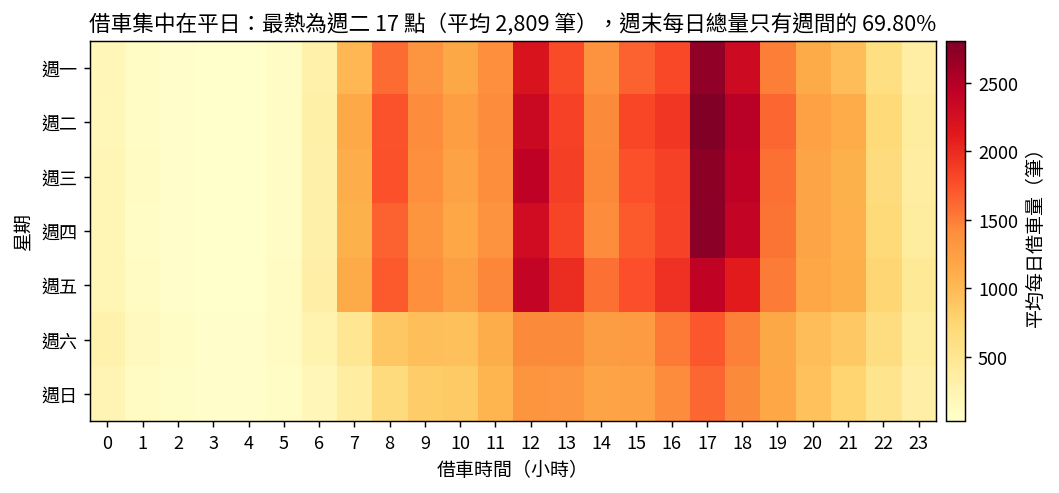

最熱的 6 個（星期, 小時）： [('週二', 17, '2,808.97'), ('週四', 17, '2,734.12'), ('週三', 17, '2,729.70'), ('週一', 17, '2,709.64'), ('週二', 18, '2,481.96'), ('週三', 18, '2,431.19')]
各星期平均每日借車量： {'週一': '25,718', '週二': '27,464', '週三': '27,071', '週四': '26,493', '週五': '27,014', '週六': '19,511', '週日': '17,834'}


In [9]:
# 3-2. 星期 × 小時熱度圖（平均每日借車量）
DOW = ["週一", "週二", "週三", "週四", "週五", "週六", "週日"]
days_per_dow = calendar.assign(dow=calendar["date"].dt.dayofweek).groupby("dow")["date"].nunique()
heat = trips.groupby(["dow", "rent_hour"]).size().unstack().div(days_per_dow, axis=0)
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24), labels=range(24))
ax.set_yticks(range(7), labels=DOW)
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("平均每日借車量（筆）")
top_cell = heat.stack().idxmax()
weekend_ratio = heat.loc[[5, 6]].sum(axis=1).mean() / heat.loc[0:4].sum(axis=1).mean()
ax.set_title(f"借車集中在平日：最熱為{DOW[top_cell[0]]} {top_cell[1]} 點（平均 {heat.to_numpy().max():,.0f} 筆），"
             f"週末每日總量只有週間的 {pct(weekend_ratio)}")
ax.set_xlabel("借車時間（小時）")
ax.set_ylabel("星期")
show_figure(fig, "fig3b_dow_hour_heatmap.png")
top_cells = heat.stack().nlargest(6)
print("最熱的 6 個（星期, 小時）：", [(DOW[d], h, fmt2(v)) for (d, h), v in top_cells.items()])
print("各星期平均每日借車量：", {DOW[d]: fmt_int(v) for d, v in heat.sum(axis=1).items()})

**解讀：** 週一到週五的型態幾乎一樣，最熱的 6 格都落在 17、18 點，週二 17 點最高（平均每日 2,808.97 筆）。週間各天的差異不大：週一 25,718 筆最低，週二 27,464 筆最高。週六、週日平均每日 19,511 和 17,834 筆，週末每日總量只有週間的 69.80%，而且沒有早上 8 點的尖峰。這張圖和上一張圖的平日／假日曲線方向一致；這裡另外確認了週間五天之間差異很小。

### 3.3 每日借車量趨勢

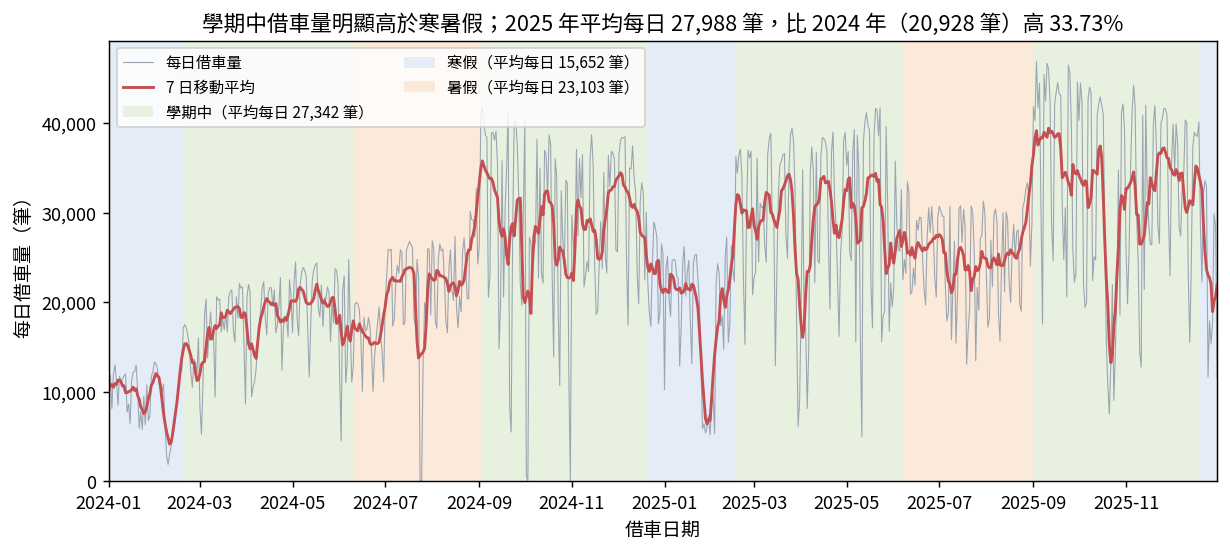

借車量最低的 5 天：


,借車量,日別,放假原因
date,,,
2024-07-25,0,假日,颱風假（凱米）
2024-10-03,0,假日,颱風假（山陀兒）
2024-10-31,65,假日,颱風假（康芮）
2024-07-24,73,假日,颱風假（凱米）
2024-10-02,582,假日,颱風假（山陀兒）


各期間平均每日借車量： {'學期中': '27,341.97', '寒假': '15,652.27', '暑假': '23,102.95'}
表 3-2　每月借車量與有借出紀錄的範圍內站點數


,借車量,平均每日借車量,有借出的範圍內站點數
month,,,
2024-01,"310,163","10,005.26",96
2024-02,"309,468","10,671.31",96
2024-03,"526,194","16,974.00",97
2024-04,"545,841","18,194.70",97
2024-05,"637,181","20,554.23",97
2024-06,"476,064","15,868.80",98
2024-07,"649,320","21,644.00",99
2024-08,"733,584","23,664.00",104
2024-09,"921,037","30,701.23",105


In [10]:
# 3-3. 每日借車量趨勢（7 日移動平均），標出學期與寒暑假
daily = trips.groupby("date").size().reindex(calendar["date"], fill_value=0)
ma7 = daily.rolling(7, center=True, min_periods=4).mean()
period_by_date = calendar.set_index("date")["period"]
period_mean = daily.groupby(period_by_date).mean()
year_mean = daily.groupby(daily.index.year).mean()

fig, ax = plt.subplots(figsize=(11, 4.4))
colors = {"學期中": "#E8F0E0", "寒假": "#E3ECF7", "暑假": "#FBE9D9"}
runs = (period_by_date != period_by_date.shift()).cumsum()
for _, block in period_by_date.groupby(runs):
    ax.axvspan(block.index[0], block.index[-1] + pd.Timedelta(days=1), color=colors[block.iloc[0]], lw=0)
ax.plot(daily.index, daily, color="#9AA5B1", linewidth=0.6, label="每日借車量")
ax.plot(ma7.index, ma7, color="#C44E52", linewidth=1.6, label="7 日移動平均")
for label, color in colors.items():
    ax.bar(0, 0, color=color, label=f"{label}（平均每日 {period_mean[label]:,.0f} 筆）")
ax.set_xlim(calendar["date"].min(), calendar["date"].max())
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 3, 5, 7, 9, 11]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title(f"學期中借車量明顯高於寒暑假；2025 年平均每日 {year_mean[2025]:,.0f} 筆，"
             f"比 2024 年（{year_mean[2024]:,.0f} 筆）高 {pct(year_mean[2025] / year_mean[2024] - 1)}")
ax.set_xlabel("借車日期")
ax.set_ylabel("每日借車量（筆）")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
show_figure(fig, "fig3c_daily_trend.png")
low_days = daily.nsmallest(5)
print("借車量最低的 5 天：")
display(pd.DataFrame({"借車量": low_days.map(fmt_int),
                      "日別": calendar.set_index("date").loc[low_days.index, "day_type"],
                      "放假原因": calendar.set_index("date").loc[low_days.index, "day_off_reason"]}))
print("各期間平均每日借車量：", {k: fmt2(v) for k, v in period_mean.items()})
monthly = trips.assign(month=trips["date"].dt.to_period("M")).groupby("month").agg(
    trips_n=("rent", "size"), days=("date", "nunique"))
monthly["active"] = (trips.loc[trips["rent_in_field"]].assign(month=lambda d: d["date"].dt.to_period("M"))
                     .groupby("month")["rent_station"].nunique())
monthly_out = pd.DataFrame({"借車量": monthly["trips_n"].map(fmt_int),
                            "平均每日借車量": (monthly["trips_n"] / monthly["days"]).map(fmt2),
                            "有借出的範圍內站點數": monthly["active"]})
monthly_out.index = monthly_out.index.astype(str)
print("表 3-2　每月借車量與有借出紀錄的範圍內站點數")
display(monthly_out)

**解讀：** 學期中平均每日 27,341.97 筆，暑假 23,102.95 筆，寒假 15,652.27 筆，寒假只有學期中的 57.25%。每次開學後，7 日移動平均都明顯跳升，例如 2025-09 開學後一度接近每日 40,000 筆。借車量最低的 5 天都是颱風假，其中 2024-07-25 和 2024-10-03 整天沒有交易。

2025 年平均每日 27,988 筆，比 2024 年的 20,928 筆高 33.73%。表 3-2 顯示，其中一部分成長來自 2024 年陸續啟用的站點：有借出紀錄的範圍內站點從 2024 年 1 月的 96 站，增加到 12 月的 107 站。但 2025 年 1 月平均每日 18,214.65 筆，仍比 2024 年 1 月的 10,005.26 筆多 82.05%，可見站數只能解釋一部分，跨年比較時需要控制站點數。

## 4. 站點分布（範圍內站點）

### 4.1 借出量與還入量

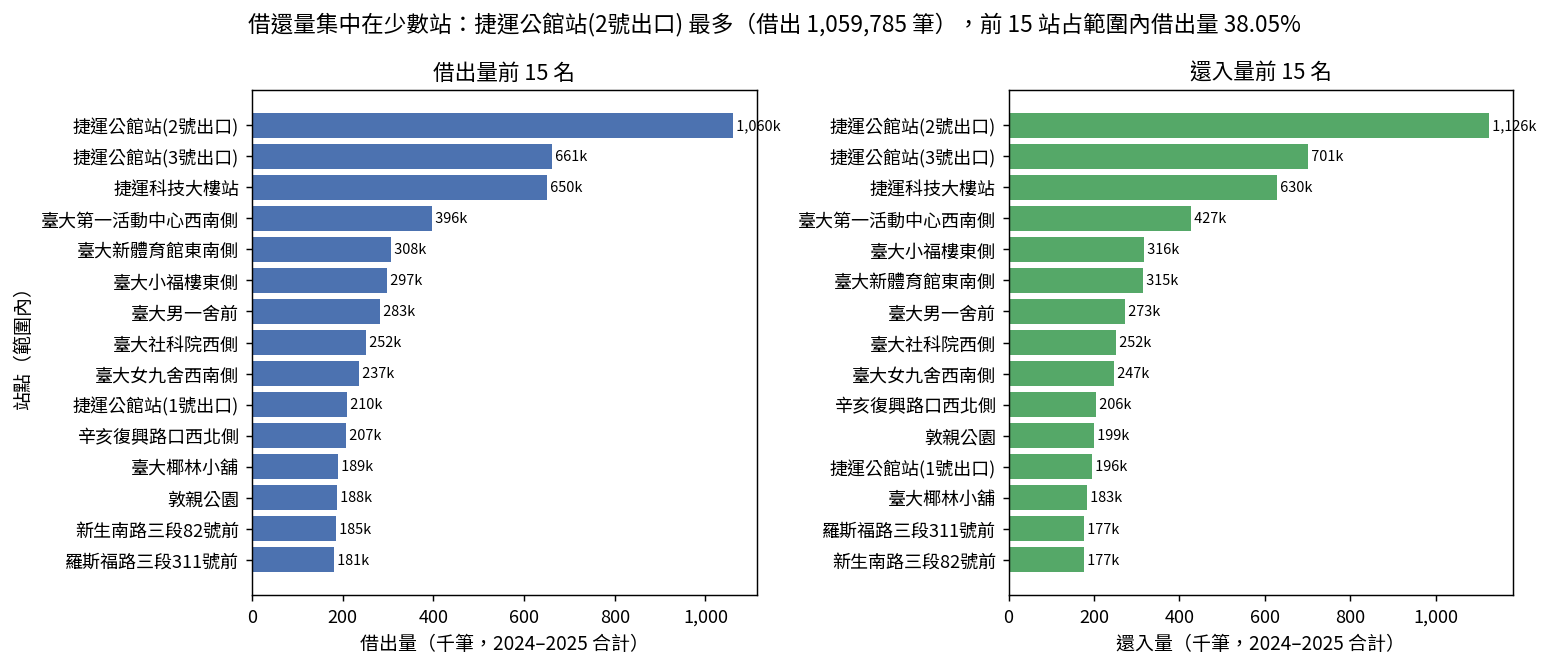

範圍內 107 站；借出量中位數 98,818 筆，最少 15,456 筆（臺大檔案展示館）。


In [11]:
# 4-1. 範圍內站點：借出量、還入量前 15 名（兩年合計）
rentals = trips.loc[trips["rent_in_field"]].groupby("rent_station", observed=True).size()
returns = trips.loc[trips["return_in_field"]].groupby("return_station", observed=True).size()
station_flow = pd.DataFrame({"借出": rentals, "還入": returns}).fillna(0).astype(int)
assert len(station_flow) == len(in_field_stations)
station_flow["淨流量"] = station_flow["還入"] - station_flow["借出"]
TOTAL_DAYS = len(calendar)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, col, color in ((axes[0], "借出", "#4C72B0"), (axes[1], "還入", "#55A868")):
    top = station_flow[col].nlargest(15).sort_values()
    ax.barh(top.index, top / 1000, color=color)
    for y, v in enumerate(top):
        ax.text(v / 1000, y, f" {v / 1000:,.0f}k", va="center", fontsize=8)
    ax.set_xlabel(f"{col}量（千筆，2024–2025 合計）")
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(f"{col}量前 15 名")
top_rent = station_flow["借出"].idxmax()
top15_share = station_flow["借出"].nlargest(15).sum() / station_flow["借出"].sum()
fig.suptitle(f"借還量集中在少數站：{top_rent} 最多（借出 {station_flow.loc[top_rent, '借出']:,} 筆），"
             f"前 15 站占範圍內借出量 {pct(top15_share)}", fontsize=12.5)
axes[0].set_ylabel("站點（範圍內）")
fig.tight_layout()
show_figure(fig, "fig4a_top_stations.png")
print(f"範圍內 {len(station_flow)} 站；借出量中位數 {station_flow['借出'].median():,.0f} 筆，"
      f"最少 {station_flow['借出'].min():,} 筆（{station_flow['借出'].idxmin()}）。")

**解讀：** 捷運公館站(2號出口) 借出 1,059,785 筆、還入 1,125,630 筆，兩項都是第一，約為第二名公館站(3號出口) 的 1.60 倍。前 3 名都是捷運站出口：公館站 2、3 號出口和科技大樓站。借出量前 15 站占範圍內借出量的 38.05%；相較之下，107 站的借出量中位數只有 98,818 筆，最少的臺大檔案展示館只有 15,456 筆。借出和還入的前 15 名是同一組站，只有排名順序略有不同。

### 4.2 淨流量

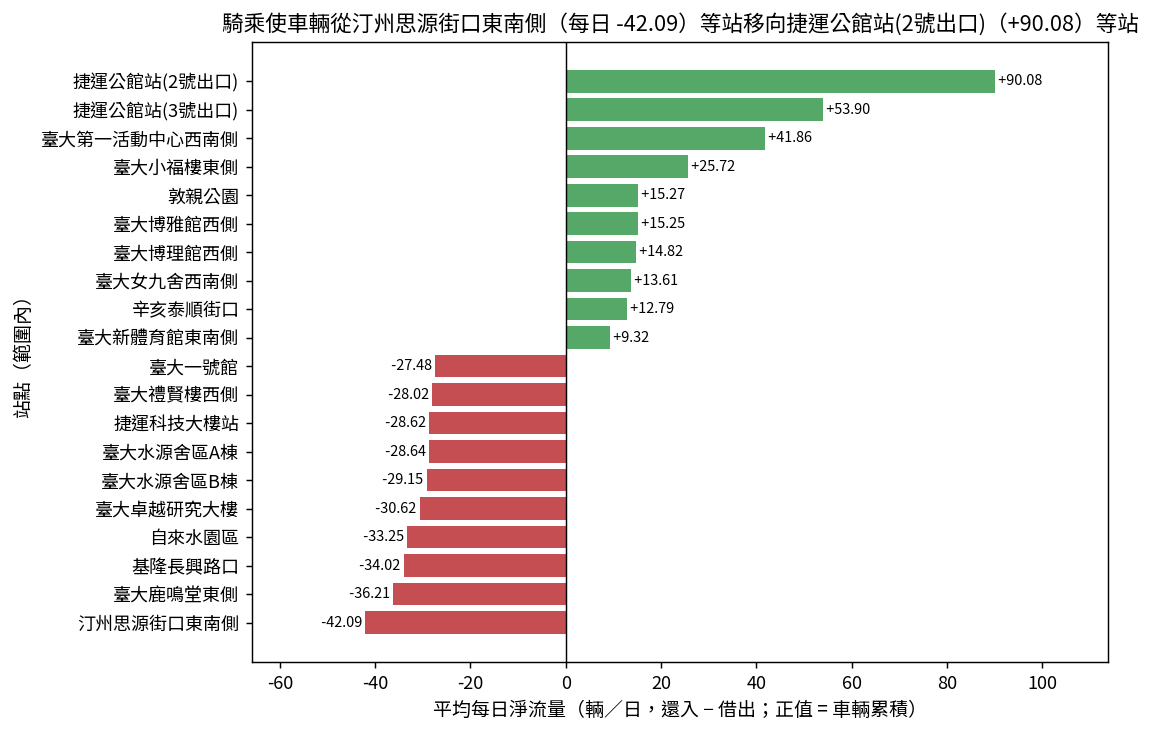

淨流量合計（全部範圍內站點，還入 − 借出）： -307,752 = 流入旅次 − 流出旅次： -307,752


In [12]:
# 4-2. 淨流量（還入 − 借出）最正、最負各 10 站；以平均每日表示（2 年共 731 天）
net_daily = (station_flow["淨流量"] / TOTAL_DAYS).sort_values()
show_net = pd.concat([net_daily.head(10), net_daily.tail(10)])
fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.barh(show_net.index, show_net, color=np.where(show_net > 0, "#55A868", "#C44E52"))
ax.axvline(0, color="black", linewidth=0.8)
for y, v in enumerate(show_net):
    ax.text(v, y, f" {v:+.2f} ", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_title(f"騎乘使車輛從{net_daily.index[0]}（每日 {net_daily.iloc[0]:+.2f}）等站"
             f"移向{net_daily.index[-1]}（{net_daily.iloc[-1]:+.2f}）等站")
ax.set_xlabel("平均每日淨流量（輛／日，還入 − 借出；正值 = 車輛累積）")
ax.set_ylabel("站點（範圍內）")
ax.margins(x=0.18)
show_figure(fig, "fig4b_netflow_extremes.png")
print("淨流量合計（全部範圍內站點，還入 − 借出）：", fmt_int(station_flow["淨流量"].sum()),
      "= 流入旅次 − 流出旅次：", fmt_int((trips["trip_type"] == "流入旅次").sum()
                                     - (trips["trip_type"] == "流出旅次").sum()))

**解讀：** 淨流量 = 還入 − 借出，正值代表騎乘會把車帶到該站。捷運公館站(2號出口) 平均每日多 90.08 輛，3 號出口多 53.90 輛，臺大第一活動中心西南側多 41.86 輛。淨流出最多的是汀州思源街口東南側（−42.09）、臺大鹿鳴堂東側（−36.21）和基隆長興路口（−34.02），水源舍區 A、B 棟與卓越研究大樓也都在名單內。

這些長期失衡在現實中要靠調度車補平。本資料只有騎乘紀錄、看不到調度，所以這裡的淨流量代表騎乘需求造成的失衡，不是站上實際車數的變化。全部範圍內站點的淨流量合計是 −307,752，正好等於流入旅次減流出旅次。

### 4.3 早晚潮汐

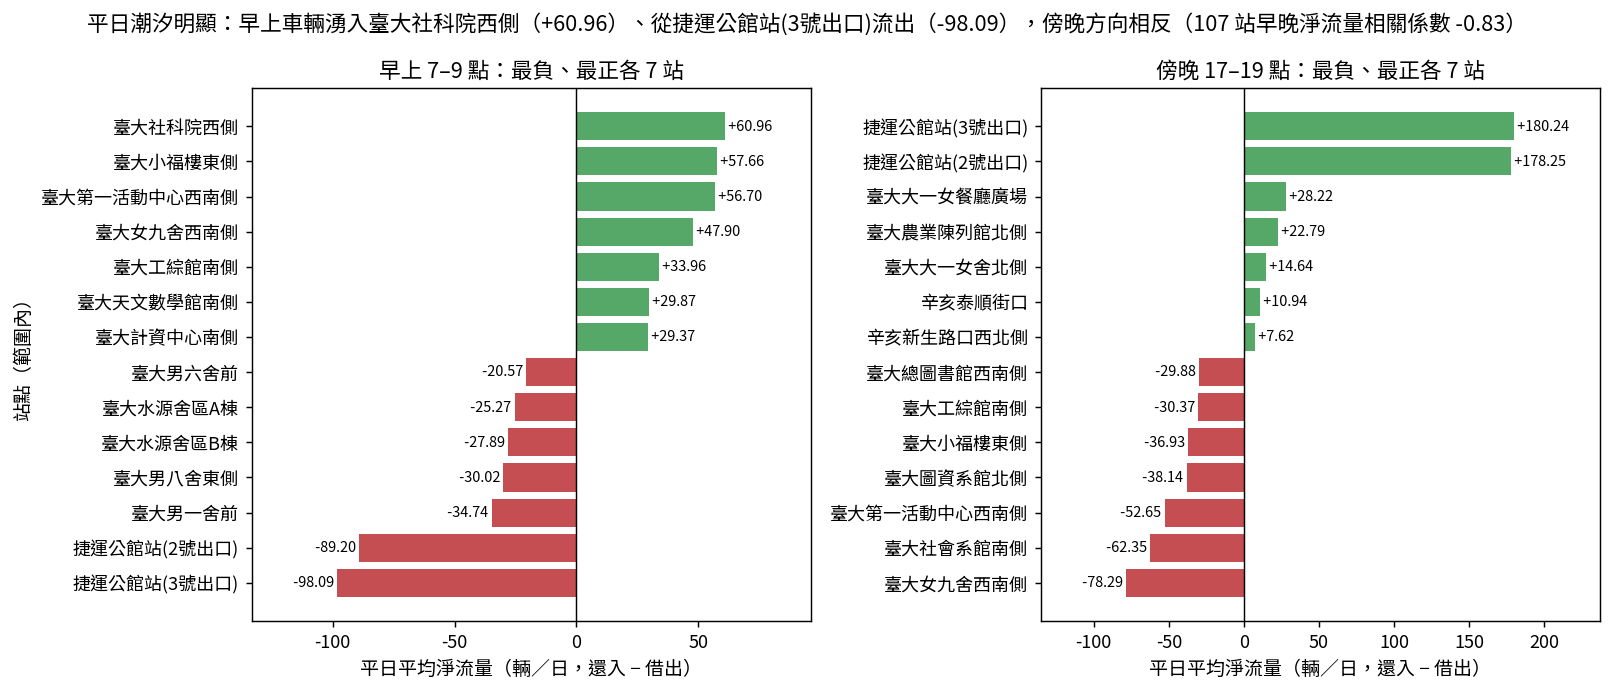

平日天數 491；早晚淨流量方向相反的站占 69.16%；相關係數 -0.83


In [13]:
# 4-3. 潮汐現象：平日早上 7–9 點（7:00–8:59）與傍晚 17–19 點（17:00–18:59）的淨流量
weekday_days = int(days_by_type["平日"])
wk = trips["day_type"] == "平日"


def window_net(hours):
    r = trips.loc[wk & trips["rent_in_field"] & trips["rent_hour"].isin(hours)].groupby("rent_station", observed=True).size()
    t = trips.loc[wk & trips["return_in_field"] & trips["return_hour"].isin(hours)].groupby("return_station", observed=True).size()
    return (t.reindex(station_flow.index, fill_value=0) - r.reindex(station_flow.index, fill_value=0)) / weekday_days


am, pm = window_net([7, 8]), window_net([17, 18])
corr = np.corrcoef(am, pm)[0, 1]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4))
for ax, series, name in ((axes[0], am, "早上 7–9 點"), (axes[1], pm, "傍晚 17–19 點")):
    s = series.sort_values()
    show = pd.concat([s.head(7), s.tail(7)])
    ax.barh(show.index, show, color=np.where(show > 0, "#55A868", "#C44E52"))
    ax.axvline(0, color="black", linewidth=0.8)
    for y, v in enumerate(show):
        ax.text(v, y, f" {v:+.2f} ", va="center", ha="left" if v > 0 else "right", fontsize=8)
    ax.margins(x=0.22)
    ax.set_title(f"{name}：最負、最正各 7 站")
    ax.set_xlabel("平日平均淨流量（輛／日，還入 − 借出）")
axes[0].set_ylabel("站點（範圍內）")
fig.suptitle(f"平日潮汐明顯：早上車輛湧入{am.idxmax()}（{am.max():+.2f}）、從{am.idxmin()}流出（{am.min():+.2f}），"
             f"傍晚方向相反（107 站早晚淨流量相關係數 {corr:.2f}）", fontsize=12)
fig.tight_layout()
show_figure(fig, "fig4c_tidal_am_pm.png")
both = pd.DataFrame({"早上淨流量": am, "傍晚淨流量": pm})
flip = ((both["早上淨流量"] * both["傍晚淨流量"]) < 0).mean()
print(f"平日天數 {weekday_days}；早晚淨流量方向相反的站占 {pct(flip)}；相關係數 {corr:.2f}")

**解讀：** 平日（491 天）的早晚流向幾乎相反：107 站早上和傍晚淨流量的相關係數是 −0.83，69.16% 的站早晚正負號相反。早上 7–9 點，車從捷運公館站 3 號（−98.09）、2 號出口（−89.20）和宿舍區（男一舍 −34.74、男八舍 −30.02、水源舍區 A／B 棟）流向社科院（+60.96）、小福樓（+57.66）、第一活動中心（+56.70）等教學區。傍晚 17–19 點方向反過來：公館站 3 號、2 號出口每日各湧入 +180.24 和 +178.25 輛，臺大女九舍西南側（−78.29）和社會系館南側（−62.35）流出最多。傍晚湧入公館站的量大約是早上流出的兩倍，和平日 17 點是全天最高峰一致。

### 4.4 熱門起訖站組合

In [14]:
# 4-4. 前 20 名熱門起訖站組合（含方向；兩年合計）
od = (trips.groupby(["rent_station", "return_station", "trip_type"], observed=True).size()
           .sort_values(ascending=False).head(20).reset_index(name="旅次數"))
od_median = (trips.set_index(["rent_station", "return_station"])["duration_min"]
             .groupby(level=[0, 1], observed=True).median())
od["時長中位數（分）"] = [fmt2(od_median.loc[(a, b)]) for a, b in zip(od["rent_station"], od["return_station"])]
od["占全部旅次"] = (od["旅次數"] / N).map(pct)
od["旅次數"] = od["旅次數"].map(fmt_int)
od.index = range(1, 21)
od = od.rename(columns={"rent_station": "借車站", "return_station": "還車站", "trip_type": "旅次類型"})
od["同站"] = np.where(od["借車站"].astype(str) == od["還車站"].astype(str), "是", "")
print(f"表 4-1　前 20 名起訖站組合（N = {N:,}）")
display(od)

表 4-1　前 20 名起訖站組合（N = 17,875,272）


,借車站,還車站,旅次類型,旅次數,時長中位數（分）,占全部旅次,同站
1,臺灣科技大學後門,捷運公館站(2號出口),流入旅次,"126,322",5.77,0.71%,
2,臺灣科技大學側門,捷運公館站(2號出口),流入旅次,"122,564",4.45,0.69%,
3,捷運公館站(2號出口),臺灣科技大學後門,流出旅次,"114,114",6.18,0.64%,
4,捷運公館站(2號出口),臺灣科技大學側門,流出旅次,"104,344",4.60,0.58%,
5,臺大男一舍前,捷運公館站(2號出口),區內旅次,"49,206",6.72,0.28%,
6,臺大第一活動中心西南側,捷運公館站(3號出口),區內旅次,"48,503",4.35,0.27%,
7,捷運公館站(2號出口),臺大男一舍前,區內旅次,"38,446",7.22,0.22%,
8,捷運公館站(3號出口),臺大第一活動中心西南側,區內旅次,"37,721",4.20,0.21%,
9,捷運科技大樓站,敦親公園,區內旅次,"34,339",4.57,0.19%,
10,敦親公園,捷運科技大樓站,區內旅次,"32,903",4.00,0.18%,


**解讀：** 前 4 名都是臺科大後門、側門和捷運公館站(2號出口) 之間的往返，每組 104,344–126,322 筆，合計 467,344 筆、占全部旅次 2.61%。這 4 組都是流入或流出旅次，代表研究範圍內最大的單一需求，其實來自範圍外臺科大學生的捷運接駁。區內最熱的組合是臺大男一舍前→公館站(2號出口)（49,206 筆）和第一活動中心西南側→公館站(3號出口)（48,503 筆）。前 20 組中有 17 組的一端是捷運公館站，其餘 3 組的一端是捷運科技大樓站；時長中位數都在 3.87–7.22 分鐘之間，也都沒有同站借還。

## 5. 與範圍外站點的往來

In [15]:
# 5. 範圍外的往來：流入旅次的外部借車站、流出旅次的外部還車站前 10 名
inflow = trips.loc[trips["trip_type"] == "流入旅次", "rent_station"].value_counts()
outflow = trips.loc[trips["trip_type"] == "流出旅次", "return_station"].value_counts()
n_in, n_out = int(inflow.sum()), int(outflow.sum())
outside_table = pd.DataFrame({
    "流入：外部借車站": inflow.head(10).index, "流入筆數": inflow.head(10).map(fmt_int).to_numpy(),
    "占流入旅次": (inflow.head(10) / n_in).map(pct).to_numpy(),
    "流出：外部還車站": outflow.head(10).index, "流出筆數": outflow.head(10).map(fmt_int).to_numpy(),
    "占流出旅次": (outflow.head(10) / n_out).map(pct).to_numpy()}, index=range(1, 11))
print(f"表 5-1　最常往來的範圍外站點前 10 名（流入 N = {n_in:,}，流出 N = {n_out:,}；"
      f"外部站點數：流入 {inflow.size:,} 站、流出 {outflow.size:,} 站）")
display(outside_table)
print(f"前 10 個外部站點占流入 {pct(inflow.head(10).sum() / n_in)}、占流出 {pct(outflow.head(10).sum() / n_out)}。")

表 5-1　最常往來的範圍外站點前 10 名（流入 N = 3,931,601，流出 N = 4,239,353；外部站點數：流入 1,638 站、流出 2,690 站）


,流入：外部借車站,流入筆數,占流入旅次,流出：外部還車站,流出筆數,占流出旅次
1,臺灣科技大學側門,"243,585",6.20%,臺灣科技大學後門,"258,804",6.10%
2,臺灣科技大學後門,"242,262",6.16%,臺灣科技大學側門,"231,479",5.46%
3,捷運臺電大樓站(2號出口),"85,887",2.18%,捷運臺電大樓站(2號出口),"83,101",1.96%
4,大安運動中心,"75,949",1.93%,大安運動中心,"72,297",1.71%
5,捷運臺電大樓站(2號出口)_1,"71,414",1.82%,臺灣科技大學正門,"68,970",1.63%
6,臺灣科技大學正門,"69,044",1.76%,捷運臺電大樓站(2號出口)_1,"63,645",1.50%
7,師大公館校區學二舍,"65,556",1.67%,師大公館校區學二舍,"60,645",1.43%
8,臺灣師範大學(圖書館),"55,127",1.40%,臺灣師範大學(圖書館),"59,264",1.40%
9,和平龍泉街口,"54,050",1.37%,和平龍泉街口,"56,256",1.33%
10,捷運臺電大樓站(1號出口),"52,089",1.32%,臺北市立圖書館(總館),"51,726",1.22%


前 10 個外部站點占流入 25.82%、占流出 23.73%。


**解讀：** 流入旅次來自 1,638 個外部站點，流出旅次去到 2,690 個，但高度集中：前 10 個外部站點就占流入的 25.82%、流出的 23.73%。臺科大的側門、後門、正門合計占流入 14.12%、流出 13.19%；其次是捷運臺電大樓站、大安運動中心和師大公館校區。

名單中「捷運臺電大樓站(2號出口)」和「捷運臺電大樓站(2號出口)_1」是兩個不同站名，可能是同一地點的兩座站；合計流入 157,301 筆，是第三大來源。大安運動中心在舊的 78 站清單中，目前不在研究範圍內，但它是流入、流出都排第 4 的外部站點。

## 總結

### 5 個最重要的資料特徵

1. **捷運接駁是核心需求**：捷運公館站(2號出口) 的借出和還入都是第一（各約 106 萬、113 萬筆）。前 3 大站都是捷運出口，前 20 名熱門起訖組合中有 17 組的一端是公館站。
2. **平日三峰加上強烈潮汐**：平日在 8、12、17 點出現尖峰。107 站早晚淨流量的相關係數是 −0.83：早上車從公館站和宿舍流向教學區，傍晚反向，公館站每日湧入約 +180 輛。
3. **以短程為主，跨界旅次較長**：時長中位數 7.37 分，50.05% 落在 5–15 分鐘；區內 5.77 分，流出和流入分別是 10.98 和 9.98 分。
4. **學期節律明顯，跨年有成長**：寒假平均每日借車量只有學期中的 57.25%，颱風假幾乎歸零；2025 年平均每日比 2024 年多 33.73%。
5. **將近一半的旅次跨出研究範圍**：流出加流入占 45.71%，最大的外部往來對象是臺科大（流入 14.12%、流出 13.19%）。

### 資料品質問題

- **時間只精確到小時**：無法分析小時內的時序，也無法分辨結伴同行和重複紀錄；「只差秒數」的疑似重複最多 3,124,387 筆（17.48%），應視為上限。
- **完全重複**：152,572 筆（0.85%）連秒數都相同，比較可能是紀錄重複。是否去重，需要在正式分析前決定。
- **時長異常值**：≤ 1 分鐘 25,248 筆，> 4 小時 14,790 筆，最長約 10 年；另有 16 筆的借還小時差和 `rent` 時長不一致。平均數類的統計需要先處理這些值。
- **車種欄位**：2024-01～10 原始檔沒有車種，占全部旅次 33.02%，跨期的車種比較只能用 2024-11 以後的資料。
- **站點涵蓋範圍隨時間變化**：範圍內有借出紀錄的站點在 2024 年從 96 站增加到 107 站；2025 年才出現的新站（如臺大人文館、羅斯福路三段283巷）不在清單內，其交易一端記為 -1。跨年比較需要控制站點數。
- **站名不一致**：有 4 格空白站名和 885 格無法辨識的站名；同一地點可能有多個站名（如「捷運臺電大樓站(2號出口)」與「…_1」）。
- **淨流量不含調度**：淨流量只反映騎乘造成的失衡，不能直接當作站上車數的變化。

### 3 個值得深入分析的方向

1. **調度與缺車**：合併站點剩餘數量 panel（`youbike_flow_hourly_2024.parquet`），比較 OD 淨流量和實際車數變化。兩者的差可以估計調度量，再找出公館站傍晚滿柱、教學區早上缺車的時段。
2. **臺科大—公館走廊**：前 4 大起訖組合都在這條走廊上，而且都跨出研究範圍。可以評估是否把臺科大三個站和臺電大樓站納入範圍，或在模型中把跨界旅次獨立處理。
3. **站點 × 小時需求模型**：以借車量或淨流量為被解釋變數，納入平日、學期、天氣和站點固定效果，估計學期與降雨的效果，並在控制站點數後檢驗 2024→2025 的成長是否仍然存在。

### 完整程式碼與重跑方式

本報告的完整程式碼就是 notebook 中依序排列的 code cell（載入套件 → 讀檔與變數建立 → 摘要統計 → 第 1–5 節分析）。Jupyter 的格式需要每段程式碼緊接著它的輸出，所以程式碼沒有另外集中貼到最後，以免同一份程式碼出現兩次。重跑方式如下：

1. 在含 `AGENTS.md` 的專案根目錄或其子資料夾開啟本 notebook，從頭依序執行全部 cell（Run All）。
2. 需要的套件：`pandas`、`numpy`、`matplotlib`、`IPython`，以及繁體中文字型（優先使用 Noto Sans TC，找不到時依序改用其他常見字型）。
3. 第 2 個 code cell 會先核對 4 個輸入檔的 SHA-256；檔案有任何變動都會停下來，不會讀到其他版本。
4. 讀檔約 1 分鐘，記憶體約需 6 GB。圖檔會寫入 `finding/youbike_traffic_eda_figures/`。

**執行狀態**：2026-11-08 在全新的 Python（IPython）程序中由上而下完整執行一次。本機沒有安裝 Jupyter，所以不是在 Jupyter kernel 中執行；本 notebook 中的所有表格、圖和數字都來自這次執行的實際輸出。
